# Credit Risk Assessment — End-to-End Machine Learning Notebook

**Objective:** Build a reproducible credit-risk classification workflow, from data understanding to saving a trained model pipeline.

> Important: Confirm from the dataset documentation whether `loan_status = 1` means default. This is a portfolio project, not a production lending decision system. Validate feature timing, fairness, calibration, and applicable requirements before any real-world use.

---

## 1. Imports and configuration

In [4]:
from pathlib import Path
import warnings
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV,
    cross_validate
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    f1_score,
    precision_score,
    recall_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.base import clone

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
warnings.filterwarnings("default")

RANDOM_STATE = 42
DATA_PATH = Path("../data/raw/credit_risk_dataset.csv")
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

## 2. Load the data

In [5]:
df_raw = pd.read_csv("credit_risk_dataset.csv")

print("Dataset shape:", df_raw.shape)
display(df_raw.head())

Dataset shape: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


## 3. Data understanding

In [6]:
print("Shape:", df_raw.shape)
print("\nColumns:")
print(df_raw.columns.tolist())

print("\nData types and non-null counts:")
df_raw.info()

print("\nNumerical summary:")
display(df_raw.describe().T)

print("\nCategorical summary:")
display(df_raw.describe(include=["object", "category"]).T)

Shape: (32581, 12)

Columns:
['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 325

,count,mean,std,min,25%,50%,75%,max
person_age,32581.0,27.734600,6.348078,20.00,23.00,26.00,30.00,144.00
person_income,32581.0,66074.848470,61983.119168,4000.00,38500.00,55000.00,79200.00,6000000.00
person_emp_length,31686.0,4.789686,4.142630,0.00,2.00,4.00,7.00,123.00
loan_amnt,32581.0,9589.371106,6322.086646,500.00,5000.00,8000.00,12200.00,35000.00
loan_int_rate,29465.0,11.011695,3.240459,5.42,7.90,10.99,13.47,23.22
loan_status,32581.0,0.218164,0.413006,0.00,0.00,0.00,0.00,1.00
loan_percent_income,32581.0,0.170203,0.106782,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,32581.0,5.804211,4.055001,2.00,3.00,4.00,8.00,30.00



Categorical summary:


C:\Users\jaman\AppData\Local\Temp\ipykernel_21228\3308572155.py:12: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df_raw.describe(include=["object", "category"]).T)


,count,unique,top,freq
person_home_ownership,32581,4,RENT,16446
loan_intent,32581,6,EDUCATION,6453
loan_grade,32581,7,A,10777
cb_person_default_on_file,32581,2,N,26836


### 3.1 Missing values

,missing_count,missing_percentage
loan_int_rate,3116,9.56
person_emp_length,895,2.75
person_income,0,0.00
person_age,0,0.00
person_home_ownership,0,0.00
loan_intent,0,0.00
loan_grade,0,0.00
loan_amnt,0,0.00
loan_status,0,0.00
loan_percent_income,0,0.00


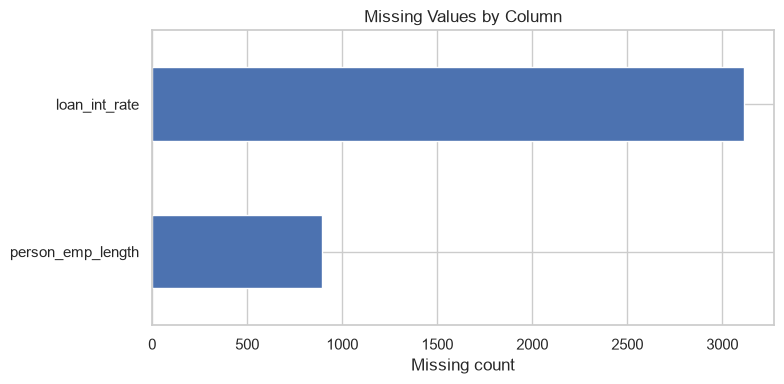

In [7]:
missing_summary = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_percentage": (df_raw.isna().mean() * 100).round(2)
}).sort_values("missing_percentage", ascending=False)

display(missing_summary)

missing_counts = df_raw.isna().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values()

if not missing_counts.empty:
    missing_counts.plot(kind="barh", figsize=(8, 4))
    plt.title("Missing Values by Column")
    plt.xlabel("Missing count")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")

### 3.2 Duplicate rows

In [8]:
duplicate_count = df_raw.duplicated().sum()
print("Exact duplicate rows:", duplicate_count)

# Inspect examples before deciding whether duplicates are genuine.
display(df_raw[df_raw.duplicated(keep=False)].head(10))

Exact duplicate rows: 165


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
14,23,115000,RENT,2.0,EDUCATION,A,35000,7.90,0,0.30,N,4
238,22,183000,MORTGAGE,3.0,EDUCATION,A,1000,NaN,0,0.01,N,2
252,24,85000,RENT,5.0,MEDICAL,B,25000,10.62,0,0.29,N,4
591,26,20000,MORTGAGE,5.0,MEDICAL,A,4800,5.99,0,0.24,N,3
740,21,21600,OWN,NaN,VENTURE,A,7125,6.99,0,0.33,N,3
817,22,22000,OWN,1.0,DEBTCONSOLIDATION,D,8500,15.05,0,0.39,N,4
920,26,50000,RENT,10.0,PERSONAL,B,18950,NaN,1,0.38,N,3
1094,22,24449,OWN,2.0,VENTURE,B,1800,11.89,0,0.07,N,4
1142,25,60000,RENT,3.0,PERSONAL,A,17000,6.91,0,0.28,N,2
1453,23,20400,RENT,2.0,MEDICAL,A,1200,7.90,0,0.06,N,2


### 3.3 Target distribution

Target counts:


loan_status
0    25473
1     7108
Name: count, dtype: int64

Target percentages:


loan_status
0    78.18
1    21.82
Name: proportion, dtype: float64

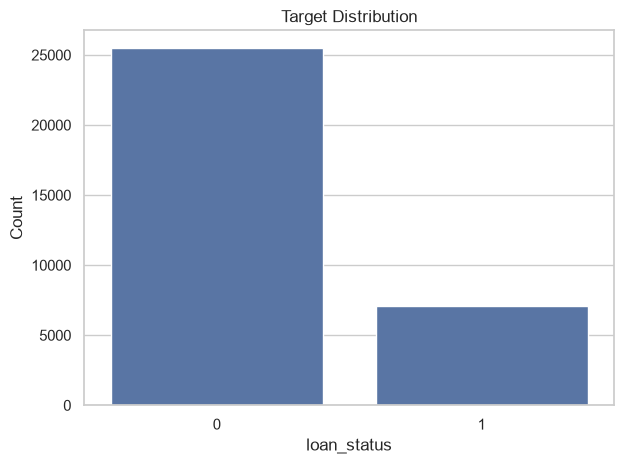

In [9]:
TARGET = "loan_status"

print("Target counts:")
display(df_raw[TARGET].value_counts(dropna=False).sort_index())

print("Target percentages:")
display((df_raw[TARGET].value_counts(normalize=True, dropna=False) * 100).round(2))

sns.countplot(data=df_raw, x=TARGET)
plt.title("Target Distribution")
plt.xlabel(TARGET)
plt.ylabel("Count")
plt.tight_layout()
plt.show()

## 4. Exploratory data analysis (EDA)

### 4.1 Identify feature types

In [10]:
numerical_columns = df_raw.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df_raw.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numerical_features_eda = [c for c in numerical_columns if c != TARGET]

print("Numerical features:", numerical_features_eda)
print("Categorical features:", categorical_columns)

Numerical features: ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']
Categorical features: ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']


C:\Users\jaman\AppData\Local\Temp\ipykernel_21228\1689787552.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df_raw.select_dtypes(


### 4.2 Numerical distributions

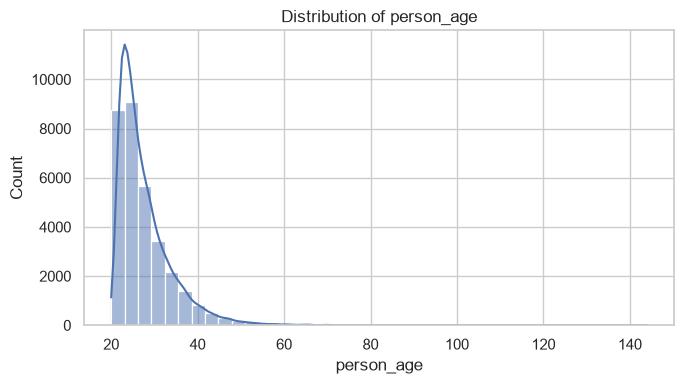

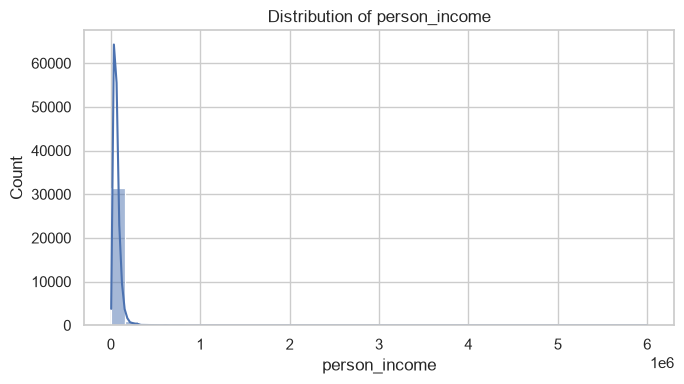

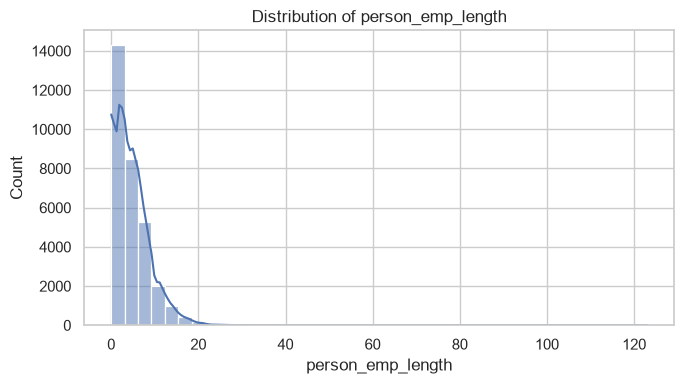

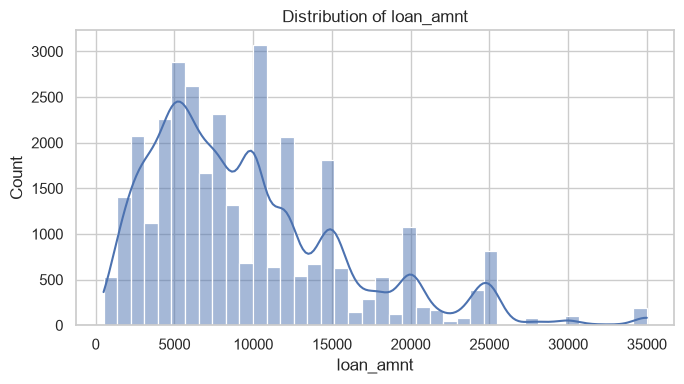

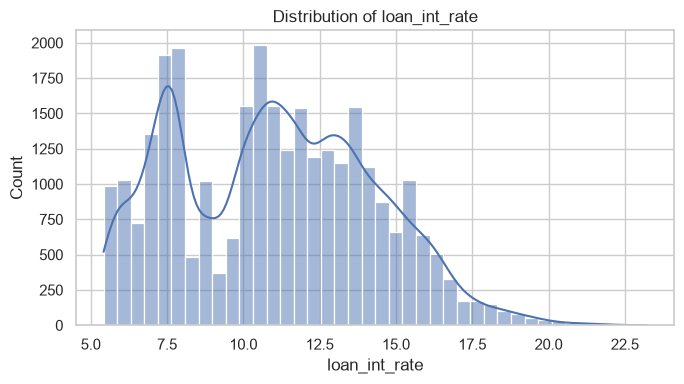

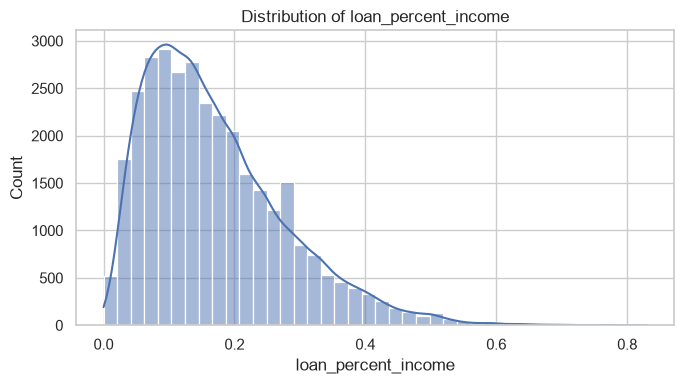

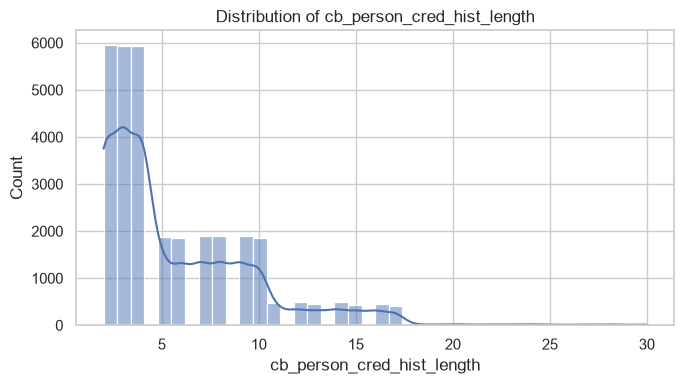

In [11]:
for col in numerical_features_eda:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=df_raw, x=col, bins=40, kde=True)
    plt.title(f"Distribution of {col}")
    plt.tight_layout()
    plt.show()

### 4.3 Categorical counts

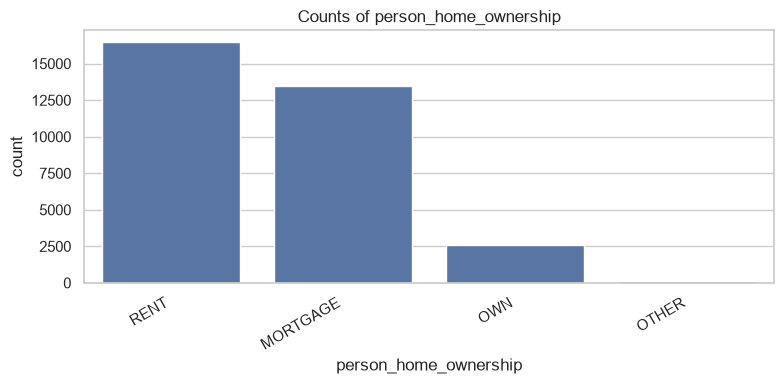

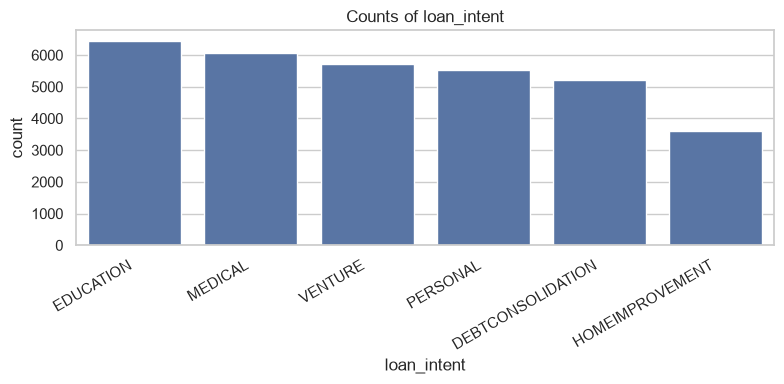

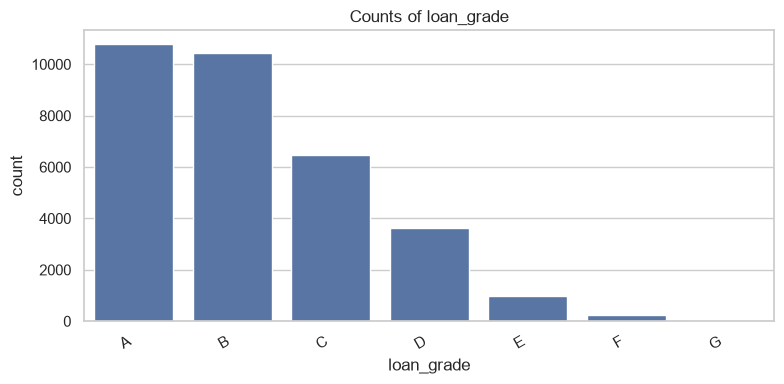

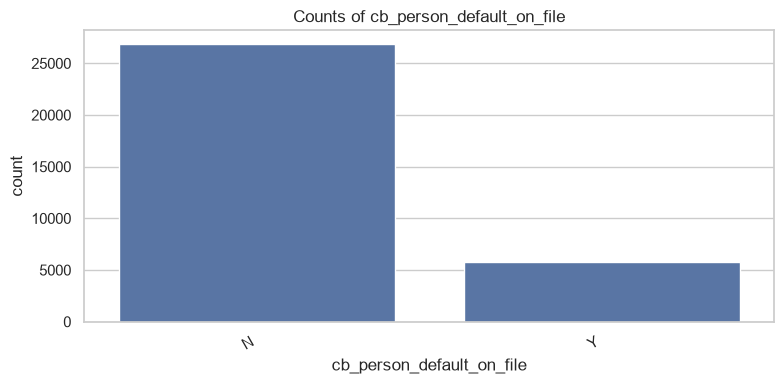

In [12]:
for col in categorical_columns:
    plt.figure(figsize=(8, 4))
    order = df_raw[col].value_counts(dropna=False).index
    sns.countplot(data=df_raw, x=col, order=order)
    plt.title(f"Counts of {col}")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

### 4.4 Skewness and outlier inspection

,skewness
person_income,32.865349
person_emp_length,2.614455
person_age,2.581393
cb_person_cred_hist_length,1.661790
loan_amnt,1.192477
loan_percent_income,1.064669
loan_int_rate,0.208550


c:\Users\jaman\.conda\envs\ds_project\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


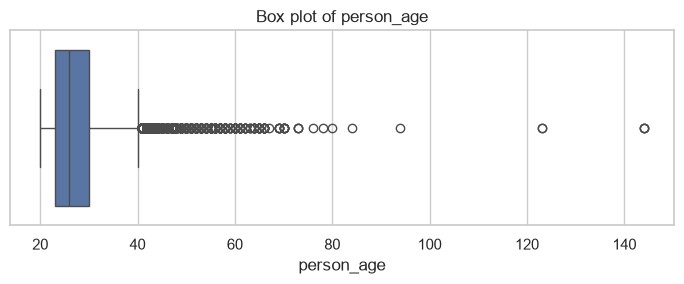

c:\Users\jaman\.conda\envs\ds_project\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


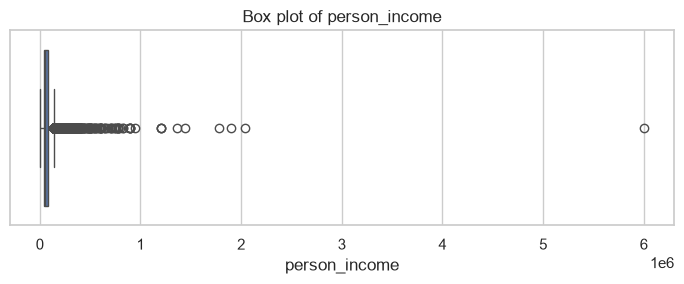

c:\Users\jaman\.conda\envs\ds_project\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


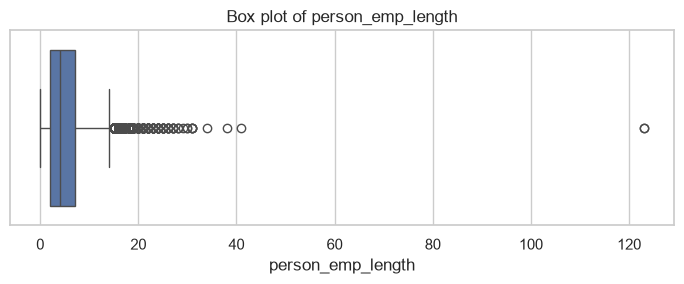

c:\Users\jaman\.conda\envs\ds_project\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


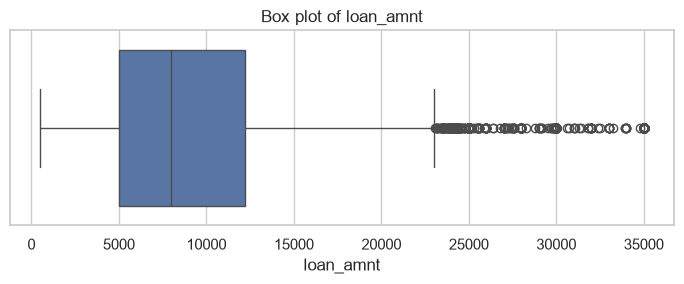

c:\Users\jaman\.conda\envs\ds_project\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


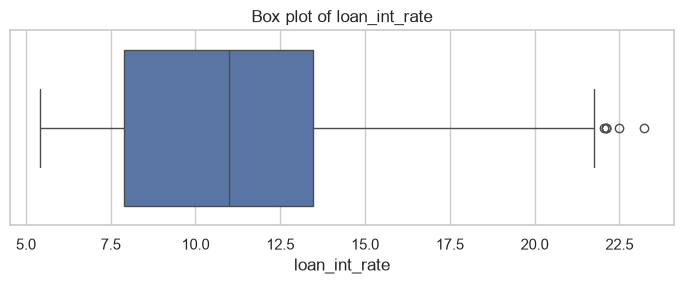

c:\Users\jaman\.conda\envs\ds_project\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


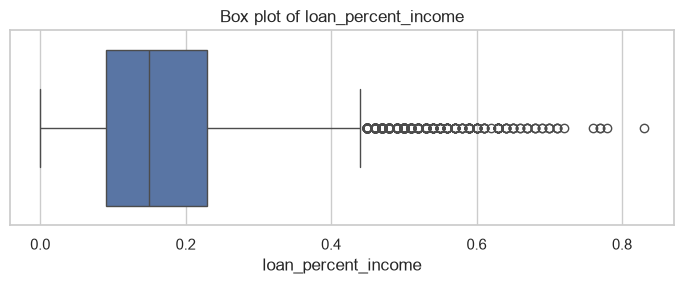

c:\Users\jaman\.conda\envs\ds_project\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


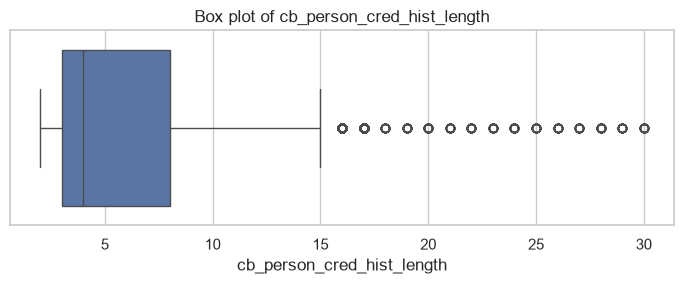

In [13]:
skewness = df_raw[numerical_features_eda].skew().sort_values(ascending=False)
display(skewness.to_frame("skewness"))

for col in numerical_features_eda:
    plt.figure(figsize=(7, 3))
    sns.boxplot(data=df_raw, x=col)
    plt.title(f"Box plot of {col}")
    plt.tight_layout()
    plt.show()

> Box plots flag unusual values; they do not prove that a record is invalid. Do not delete valid high-income borrowers or large loans automatically.

### 4.5 Default rate by categorical feature


Target-positive rate by person_home_ownership


,person_home_ownership,borrowers,positive_rate,positive_rate_pct
3,RENT,16446,0.315700,31.57
1,OTHER,107,0.308411,30.84
0,MORTGAGE,13444,0.125707,12.57
2,OWN,2584,0.074690,7.47


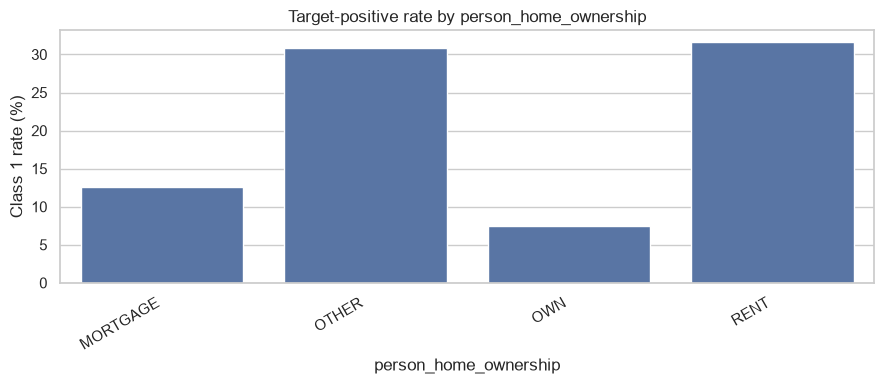


Target-positive rate by loan_intent


,loan_intent,borrowers,positive_rate,positive_rate_pct
0,DEBTCONSOLIDATION,5212,0.285879,28.59
3,MEDICAL,6071,0.267007,26.70
2,HOMEIMPROVEMENT,3605,0.261026,26.10
4,PERSONAL,5521,0.198877,19.89
1,EDUCATION,6453,0.172168,17.22
5,VENTURE,5719,0.148103,14.81


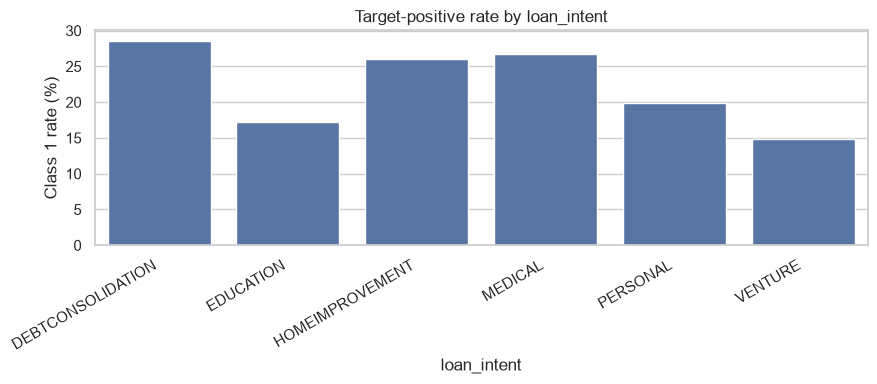


Target-positive rate by loan_grade


,loan_grade,borrowers,positive_rate,positive_rate_pct
6,G,64,0.984375,98.44
5,F,241,0.705394,70.54
4,E,964,0.644191,64.42
3,D,3626,0.590458,59.05
2,C,6458,0.207340,20.73
1,B,10451,0.162760,16.28
0,A,10777,0.099564,9.96


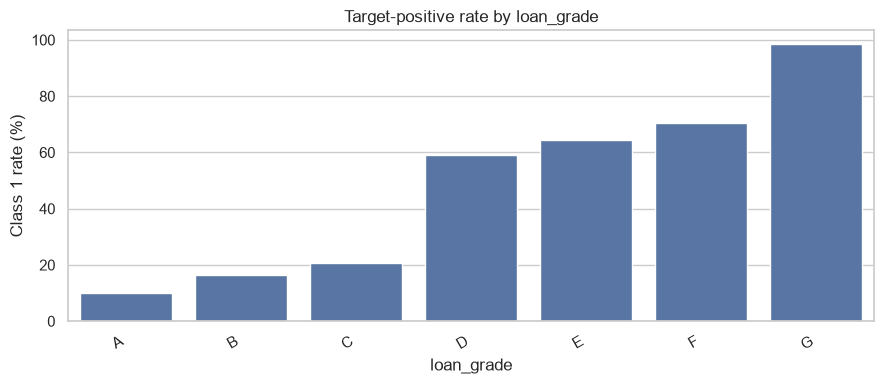


Target-positive rate by cb_person_default_on_file


,cb_person_default_on_file,borrowers,positive_rate,positive_rate_pct
1,Y,5745,0.378068,37.81
0,N,26836,0.183932,18.39


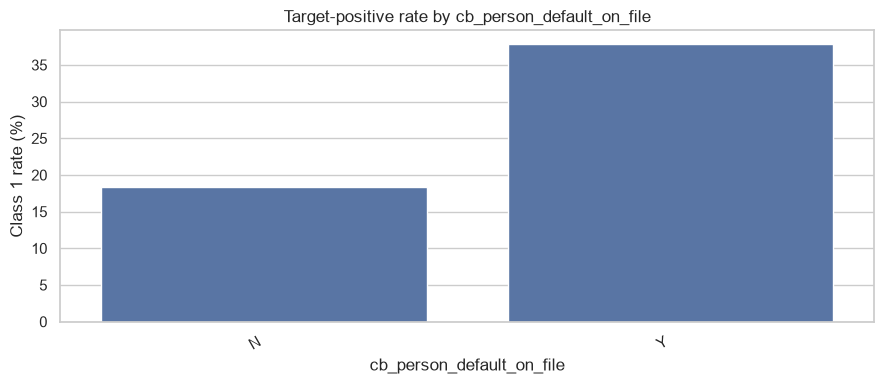

In [14]:
# Confirm from the dataset documentation that class 1 represents default
# before interpreting this as a default rate.
for col in categorical_columns:
    summary = (
        df_raw.groupby(col, dropna=False)[TARGET]
        .agg(borrowers="size", positive_rate="mean")
        .reset_index()
    )
    summary["positive_rate_pct"] = (summary["positive_rate"] * 100).round(2)

    print(f"\nTarget-positive rate by {col}")
    display(summary.sort_values("positive_rate_pct", ascending=False))

    plt.figure(figsize=(9, 4))
    sns.barplot(data=summary, x=col, y="positive_rate_pct")
    plt.title(f"Target-positive rate by {col}")
    plt.ylabel("Class 1 rate (%)")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

### 4.6 Numerical features versus target

c:\Users\jaman\.conda\envs\ds_project\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


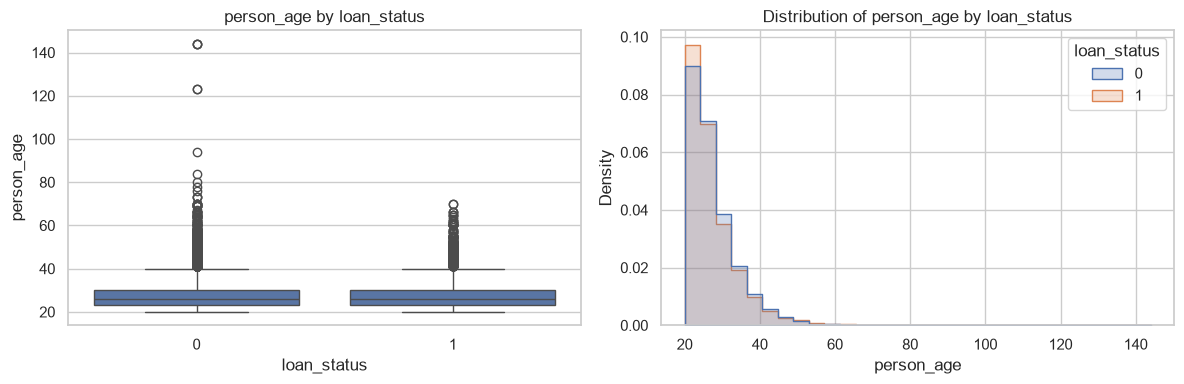

c:\Users\jaman\.conda\envs\ds_project\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


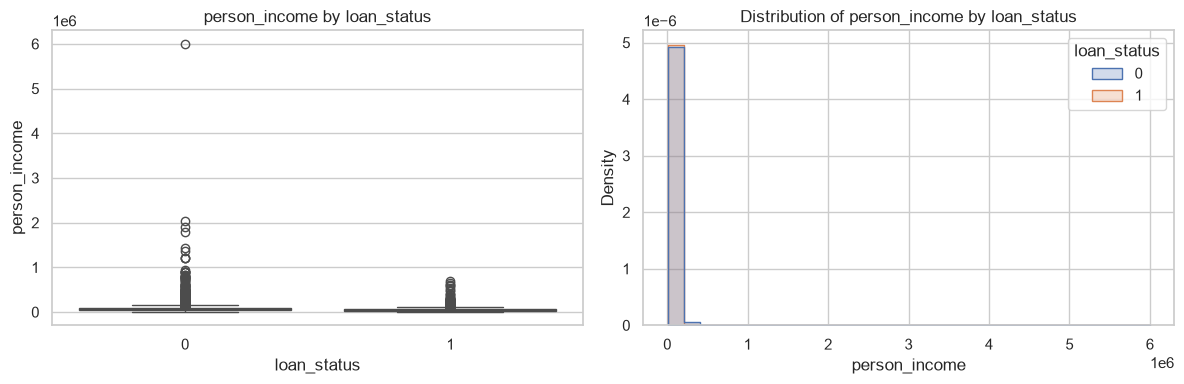

c:\Users\jaman\.conda\envs\ds_project\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


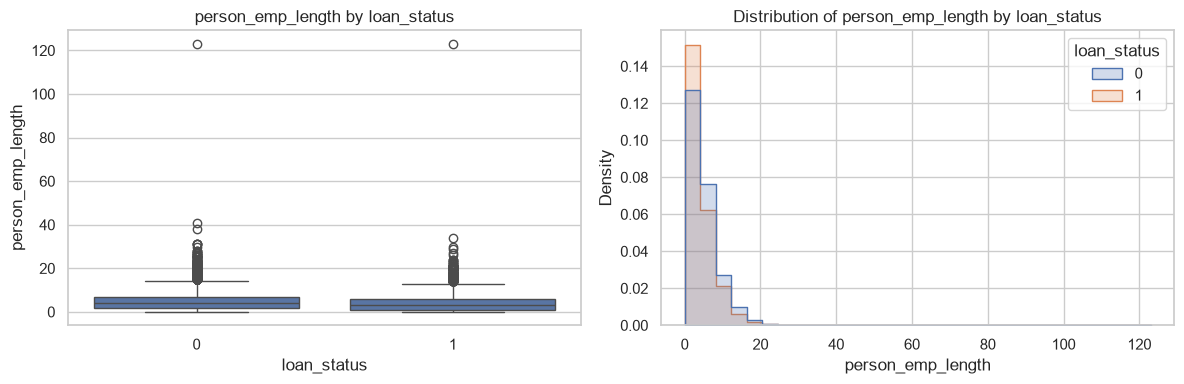

c:\Users\jaman\.conda\envs\ds_project\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


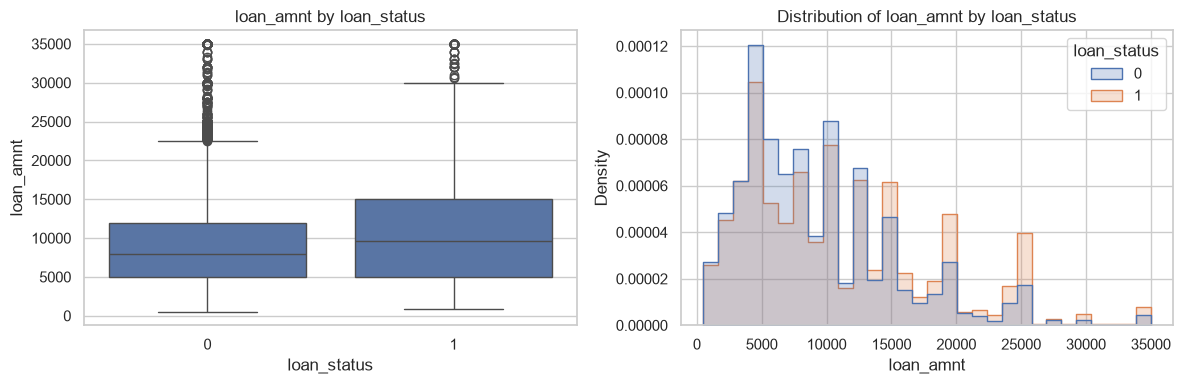

c:\Users\jaman\.conda\envs\ds_project\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


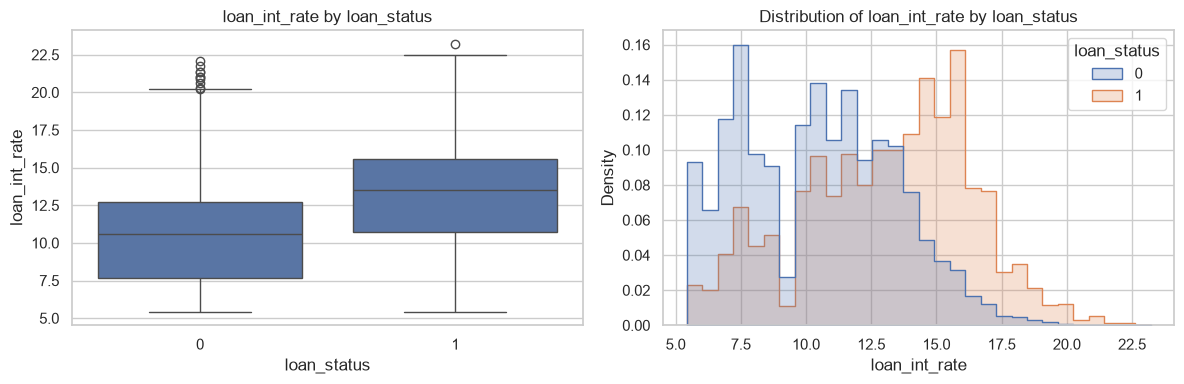

c:\Users\jaman\.conda\envs\ds_project\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


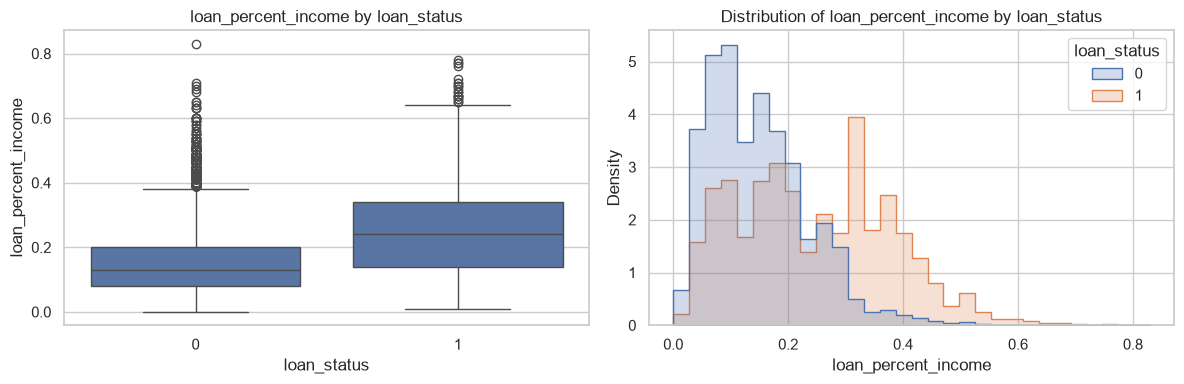

c:\Users\jaman\.conda\envs\ds_project\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


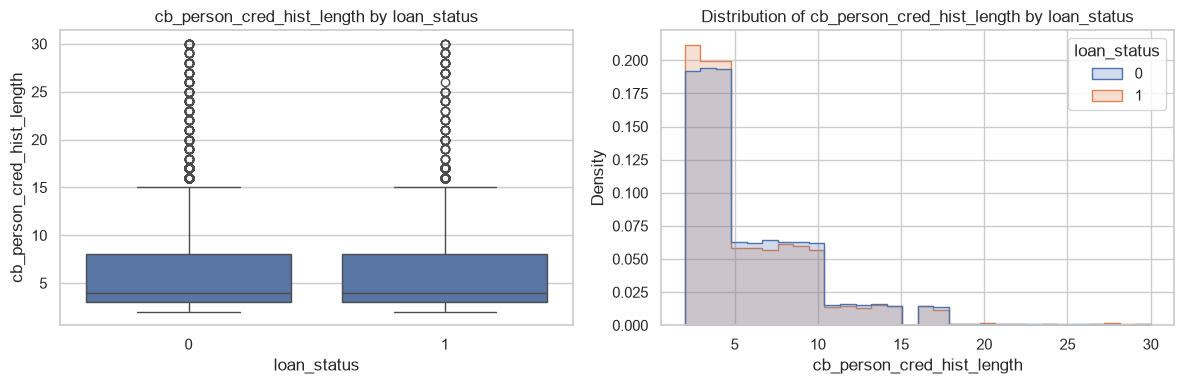

In [15]:
for col in numerical_features_eda:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.boxplot(data=df_raw, x=TARGET, y=col, ax=axes[0])
    axes[0].set_title(f"{col} by {TARGET}")

    sns.histplot(
        data=df_raw,
        x=col,
        hue=TARGET,
        bins=30,
        stat="density",
        common_norm=False,
        element="step",
        ax=axes[1]
    )
    axes[1].set_title(f"Distribution of {col} by {TARGET}")

    plt.tight_layout()
    plt.show()

### 4.7 Loan-to-income ratio

c:\Users\jaman\.conda\envs\ds_project\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


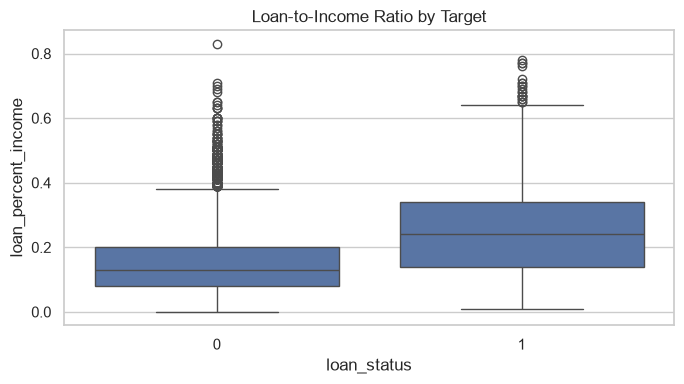

,income_ratio_group,borrowers,positive_rate,positive_rate_pct
0,<=10%,10484,0.117226,11.72
1,10-20%,12066,0.151086,15.11
2,20-30%,6197,0.219461,21.95
3,30-40%,2714,0.687178,68.72
4,>40%,1120,0.741964,74.20


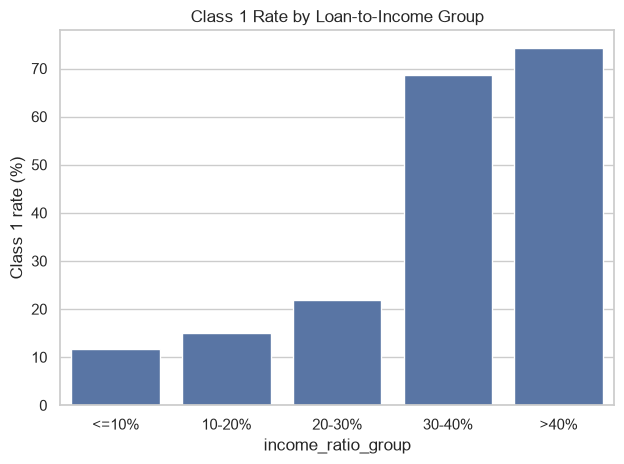

In [16]:
if "loan_percent_income" in df_raw.columns:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df_raw, x=TARGET, y="loan_percent_income")
    plt.title("Loan-to-Income Ratio by Target")
    plt.tight_layout()
    plt.show()

    df_ratio = df_raw.copy()
    df_ratio["income_ratio_group"] = pd.cut(
        df_ratio["loan_percent_income"],
        bins=[-np.inf, 0.10, 0.20, 0.30, 0.40, np.inf],
        labels=["<=10%", "10-20%", "20-30%", "30-40%", ">40%"]
    )

    ratio_summary = (
        df_ratio.groupby("income_ratio_group", observed=False)[TARGET]
        .agg(borrowers="size", positive_rate="mean")
        .reset_index()
    )
    ratio_summary["positive_rate_pct"] = (ratio_summary["positive_rate"] * 100).round(2)
    display(ratio_summary)

    sns.barplot(data=ratio_summary, x="income_ratio_group", y="positive_rate_pct")
    plt.title("Class 1 Rate by Loan-to-Income Group")
    plt.ylabel("Class 1 rate (%)")
    plt.tight_layout()
    plt.show()

### 4.8 Correlation matrix

c:\Users\jaman\.conda\envs\ds_project\Lib\site-packages\seaborn\matrix.py:243: PendingDeprecationWarning: The set_bad function will be deprecated in a future version. Use cmap.with_extremes(bad=...) or Colormap(bad=...) instead.
  self.cmap.set_bad(bad)


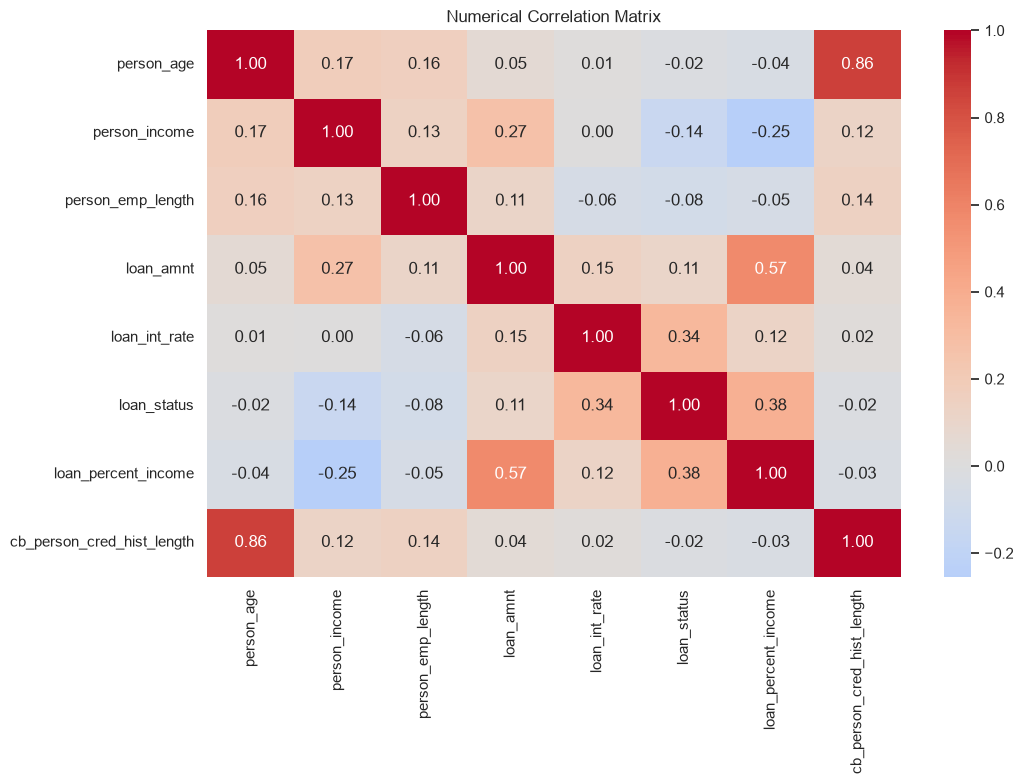

In [17]:
corr_df = df_raw.select_dtypes(include=np.number).corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr_df, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Numerical Correlation Matrix")
plt.tight_layout()
plt.show()

### 4.9 Basic data-quality checks

In [18]:
checks = {}

if "person_age" in df_raw:
    checks["age_below_18"] = int((df_raw["person_age"] < 18).sum())
if "person_emp_length" in df_raw:
    checks["negative_employment_length"] = int((df_raw["person_emp_length"] < 0).sum())
if "person_income" in df_raw:
    checks["non_positive_income"] = int((df_raw["person_income"] <= 0).sum())
if "loan_amnt" in df_raw:
    checks["non_positive_loan_amount"] = int((df_raw["loan_amnt"] <= 0).sum())

print(checks)

if {"loan_amnt", "person_income", "loan_percent_income"}.issubset(df_raw.columns):
    calculated_ratio = df_raw["loan_amnt"] / df_raw["person_income"].replace(0, np.nan)
    ratio_diff = (df_raw["loan_percent_income"] - calculated_ratio).abs()
    print("Ratio differences greater than 0.02:", int((ratio_diff > 0.02).sum()))

{'age_below_18': 0, 'negative_employment_length': 0, 'non_positive_income': 0, 'non_positive_loan_amount': 0}
Ratio differences greater than 0.02: 283


## 5. Data cleaning and feature decisions

### 5.1 Remove exact duplicates

This step assumes exact duplicate rows are accidental duplicates. If the data documentation says repeated identical records can represent separate valid loans, investigate before removing them.

In [19]:
df = df_raw.drop_duplicates().copy()
print("Rows before:", len(df_raw))
print("Rows after removing exact duplicates:", len(df))
print("Rows removed:", len(df_raw) - len(df))

Rows before: 32581
Rows after removing exact duplicates: 32416
Rows removed: 165


### 5.2 Validate target and remove rows without labels

In [20]:
if TARGET not in df.columns:
    raise ValueError(f"Target column '{TARGET}' not found.")

print("Target values:", sorted(df[TARGET].dropna().unique().tolist()))

df = df.dropna(subset=[TARGET]).copy()

if df[TARGET].nunique() != 2:
    raise ValueError("This notebook expects a binary classification target.")

# Ensure binary labels are 0 and 1.
target_values = set(df[TARGET].unique())
if target_values != {0, 1}:
    raise ValueError(
        f"Expected target labels {{0, 1}}, found {target_values}. "
        "Map labels deliberately after confirming the dataset documentation."
    )

df[TARGET] = df[TARGET].astype(int)

Target values: [0, 1]


In [21]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [22]:
df.shape

(32416, 12)

In [23]:
df.to_csv("FInal_data.csv",index=False)

## 15. Final checklist

- [ ] Confirm the meaning of target classes.
- [ ] Investigate exact duplicates before removal.
- [ ] Check missingness and suspicious values.
- [ ] Keep preprocessing inside the model pipeline.
- [ ] Select hyperparameters and threshold without using the test set for decisions.
- [ ] Review PR-AUC, recall, precision, confusion matrix, and calibration.
- [ ] Document limitations and fairness considerations.
- [ ] Save and reload-test the complete pipeline.

**Next phase after the notebook:** move stable logic into reusable Python modules, add automated tests, build a FastAPI endpoint, and then create a Streamlit interface.